### Importing libraries

In [19]:
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px
import plotly.graph_objects as go

### Importing data

In [3]:
currency_index= pd.read_csv("C:/Users/user/Desktop/Data Science/PoeMarketAnalyser/data/poeninja/currency_data_processed/currency_index.csv", sep=";", low_memory=False)
players = pd.read_csv("C:/Users/user/Desktop/Data Science/PoeMarketAnalyser/data/poeninja/players_data_processed/players_processed.csv", sep=";", low_memory=False)

# Players activity ecnomics

### Adding **Day** Column

In [4]:
#first day of each league
players["Date"] = pd.to_datetime(players["Date"])
league_start = players.groupby("League")["Date"].transform("min")

# league day
players["Day"] = (players["Date"]-league_start).dt.days + 1
players_day=players.drop(columns=["Date"]).copy()

#exporting players dataset with Day column
players_day.reset_index(drop=True).to_csv("C:/Users/user/Desktop/Data Science/PoeMarketAnalyser/data/poeninja/players_data_processed/players_processed_day.csv",sep=";",index=False)

### Merging datasets

In [5]:
economy_population = currency_index.merge(players_day,on=["League", "Day"],how="left")
economy_population.head()

,League,Day,currency_index,Players
0,Affliction,1,1.000000,144193.0
1,Affliction,2,0.687330,144326.0
2,Affliction,3,0.954545,124599.0
3,Affliction,4,1.128216,116564.0
4,Affliction,5,1.357263,109595.0


### Players number normalisation
As the number of players differ from leagues

In [6]:
# player population on day 1 
day1_players = (economy_population.sort_values(["League", "Day"]).groupby("League", as_index=False).first()[["League", "Players"]].rename(columns={"Players": "Players_day1"}))

# Merge population with day 1 players
economy_population = economy_population.merge(day1_players,on="League",how="left")

# Number of players normalisation
economy_population["Players_norm"] = (economy_population["Players"] /economy_population["Players_day1"])
economy_population.head()

,League,Day,currency_index,Players,Players_day1,Players_norm
0,Affliction,1,1.000000,144193.0,144193.0,1.000000
1,Affliction,2,0.687330,144326.0,144193.0,1.000922
2,Affliction,3,0.954545,124599.0,144193.0,0.864113
3,Affliction,4,1.128216,116564.0,144193.0,0.808389
4,Affliction,5,1.357263,109595.0,144193.0,0.760058


### Correlation between number of players and Currency Purchasing Index 

#### Currency index vs Players plot

In [24]:
fig = go.Figure()

for league, df_league in economy_population.groupby("League"):
    
    # currency index
    fig.add_trace(go.Scatter(x=df_league["Day"],y=df_league["currency_index"],name=f"{league} — currency index",yaxis="y1"))
    # player population
    fig.add_trace(go.Scatter(x=df_league["Day"],y=df_league["Players"],name=f"{league} — Players",yaxis="y2",line=dict(dash="dash")))

fig.update_layout(title="Currency index and player population in time",xaxis_title="Day of league",yaxis=dict(title="Currency index"),yaxis2=dict(title="Player population",overlaying="y",side="right"))
fig.show()

In the plot it is visible that for the Ancestor league a strong negative correlation appears: as the number of players drops, the currency index increases. In the case of the other leagues the correlation is not very clear, however there are some periods that strongly indicate it. For example, in the Settlers league around day 210 a visible spike in the number of players corresponds with a rapid decrease in the currency index. This might lead to the conclusion that at the late stage of the game in a stable league a change in the currency is only correlated with player activity.

#### Correlation calculations

Pearson correlation measures the strength of a linear relationship between two variables. In this context, it indicates whether changes in player population are proportionally associated with changes in the currency inflation index. Also Spearman correlation was used as it  measures a monotonic relationship based on the ranking of values, it is more robust to outliers, non-linear relationships, and short-term fluctuations in the data.

Using both measures increases the reliability of the analysis. If Pearson and Spearman produce similar results, it suggests that the observed relationship is consistent and not driven by extreme observations or non-linear behaviour.

In [7]:
# Pearson correlation 
pearson_corr = (economy_population.groupby("League")[["Players_norm", "currency_index"]].corr(method="pearson").unstack().iloc[:,1].reset_index(name="pearson_corr"))

# Spearman correlation 
spearman_corr = (economy_population.groupby("League")[["Players_norm", "currency_index"]].corr(method="spearman").unstack().iloc[:,1].reset_index(name="spearman_corr"))

# Merging results
correlation_summary = pearson_corr.merge(spearman_corr,on="League")
correlation_summary

,League,pearson_corr,spearman_corr
0,Affliction,-0.607559,-0.510147
1,Ancestor,-0.926210,-0.970830
2,Keepers,-0.542178,-0.426656
3,Mercenaries,-0.361334,-0.018029
4,Necropolis,-0.100340,0.405536
5,Settlers,-0.669447,-0.744255


In [13]:
fig = px.scatter( economy_population,x="Players_norm", y="currency_index",color="League",title="Player population vs currency inflation",)
fig.update_layout(xaxis_title="Normalised player population",yaxis_title="Currency purchasing power index")
fig.show()

* The results show that most leagues exhibit a negative correlation between player population and currency inflation. This means that as the number of active players declines, the currency index increases. This pattern suggests that when player population decreases, the supply of items and crafting resources likely falls faster than demand, leading to rising prices and inflation of the Chaos Orb.

* The strength of this relationship varies between leagues:

    -Ancestor shows a very strong negative correlation (Pearson −0.93, Spearman −0.97), indicating that in this case inflation was closely linked to the decline in player population and that number of players was the main factor controlling the currency index. 

    -Settlers, Affliction and Keepers Leagues show moderate negative correlation exhibits negative relationship, suggesting that the league economy was sensitive to population changes, however, with weaker effects.

    -Analysis of all the correlations calculated for Mercenaries and Necropolis leagues indicate that tehre is no relationship between population and inflation, suggesting a more stable or structurally different market.


* Across most leagues, the analysis indicates that declining player population is associated with increasing inflation, meaning that the purchasing power of Chaos Orbs tends to weaken as fewer players remain active in the league economy. 

### Player-adjusted currency index

In [15]:

economy_population["player_adjusted_index"] = (
    economy_population["currency_index"] /
    economy_population["Players_norm"]
)

economy_population.head()

,League,Day,currency_index,Players,Players_day1,Players_norm,player_adjusted_index
0,Affliction,1,1.000000,144193.0,144193.0,1.000000,1.000000
1,Affliction,2,0.687330,144326.0,144193.0,1.000922,0.686697
2,Affliction,3,0.954545,124599.0,144193.0,0.864113,1.104654
3,Affliction,4,1.128216,116564.0,144193.0,0.808389,1.395635
4,Affliction,5,1.357263,109595.0,144193.0,0.760058,1.785736


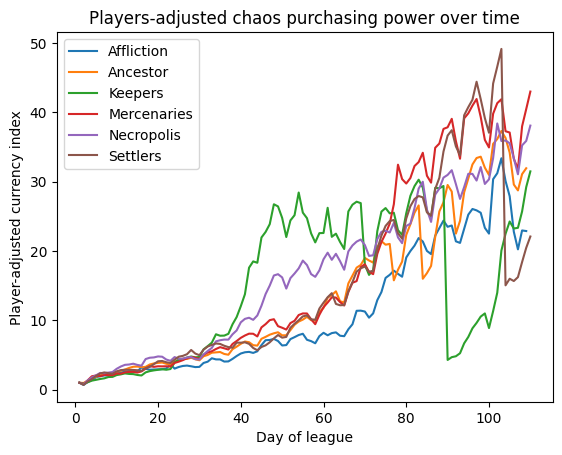

In [18]:
economy_population_day110 = economy_population[economy_population["Day"] <= 110].copy()

for league, df_league in economy_population_day110.groupby("League"):
    plt.plot(df_league["Day"],df_league["player_adjusted_index"],label=league)

plt.xlabel("Day of league")
plt.ylabel("Player-adjusted currency index")
plt.title("Players-adjusted chaos purchasing power over time")
plt.legend()
plt.show()


**Conclusions:**

1. The comparison of average inflation rates shows substantial differences between leagues. The **Ancestor** league exhibits the highest inflation levels, with weekly inflation close to 8%. In real-world economic terms, inflation at this level would be considered very high, indicating a rapid decline in the purchasing power of the currency.

2. The **Keepers** and the **Affliction** leagues also show high inflation level, while **Necropolis** and **Mercenaries** leagues show lower inflation levels, with weekly values around 4%. This range is considered as moderate inflation and suggests a relatively stable currency market.

3. The **Settlers** league exhibits the lowest inflation among the analysed leagues, with weekly inflation close to 2.5%. In real-world economics, inflation around 2-2.5% is considered ideal, low, and stable, as it allows economic activity to grow, avoiding deflation at the same time. The **Settlers** league can therefore be considered the closest representation of an economically stable market. 

4. The daily and weekly measures follow the same relative ordering across leagues, suggesting that the observed differences reflect persistent economic characteristics of each league rather than short-term market fluctuations.
